# 第 3 课 · 多项 Logit 与产品替代

同一家商店多了一件商品。每位顾客可以购买 A、购买 B，或者什么都不买。如果 A 涨价，流失的购买份额会有多少转向 B，又有多少变成不购买？

**建议用时 60 分钟。** 按顺序运行单元格。你会把[第一课](01-binary-logit.ipynb)的二元选择扩展到三个选项，用极大似然估计模型，再比较两个报价方案下的预测份额。[第二课](02-sampling-uncertainty.ipynb)讨论估计的抽样波动，本课用估计值计算份额。

## 1. 从效用到三个选择概率

记顾客 $i$ 面对的两个价格为 $p_{iA}$、$p_{iB}$。每位顾客从 A、B 和不购买（选项 $0$）中选出效用最高的一项。效用是系统性效用 $V_{ij}$ 和冲击 $\varepsilon_{ij}$ 之和。设

$$
V_{iA}=\alpha_A+\beta(p_{iA}-8),\qquad
V_{iB}=\alpha_B+\beta(p_{iB}-8),\qquad
V_{i0}=0.
$$

不购买是**外部选项**（outside option）。给三个效用同时加上同一个数，选择不会改变，所以可将外部选项的系统性效用定为零。两个商品共用价格系数 $\beta$。$\alpha_A$ 和 $\alpha_B$ 分别是其价格为 8 元时相对于不购买的系统性效用差。

假设效用冲击在顾客和选项之间独立，也与报价独立，均服从尺度为 1 的标准 Gumbel 分布。这给出**多项 Logit**（multinomial logit, MNL）选择概率

$$
P_{ij}=\frac{\exp(V_{ij})}{1+\exp(V_{iA})+\exp(V_{iB})},
\qquad j\in\{A,B,0\}.
$$

不购买的分子是 $\exp(0)=1$。三个概率之和为 1。如果货架上只有 A，两项独立标准 Gumbel 冲击的差服从标准 Logistic 分布，模型就回到第一课的二元 Logit。 [Train 教材第 3 章](https://eml.berkeley.edu/books/choice2nd/Ch03_p34-75.pdf)

## 2. 模拟报价与选择

每位顾客看到 A 和 B 的两个报价。每个报价都从 5 至 11 元的整数价中等概率抽取，两个报价彼此独立。模拟器根据三个带冲击的效用生成实际选择。每条记录保留两件商品的报价，即使顾客没有购买。

沿用第一课的 A 截距 $0.60$ 和价格系数 $-0.55$，新增 B 截距 $0.15$。两个商品同价时，A 的系统性效用较高，但顾客也可能因效用冲击而购买 B 或选择不购买。下面模拟 4,000 位顾客，随机种子为 321。

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import PercentFormatter
from scipy.optimize import minimize
from scipy.special import logsumexp


reference_price = 8
alternatives = ("A", "B", "No purchase")
true_parameters = np.array([0.60, 0.15, -0.55])


def systematic_utility(parameters, prices):
    product_utility = parameters[:2] + parameters[2] * (prices - reference_price)
    return np.column_stack((product_utility, np.zeros(len(prices))))


rng = np.random.default_rng(321)
sample_size = 4_000
prices = rng.integers(5, 12, size=(sample_size, 2))
shocks = rng.gumbel(size=(sample_size, 3))
choices = np.argmax(systematic_utility(true_parameters, prices) + shocks, axis=1)

print("样本前五位顾客")
print("A 的报价  B 的报价  选择")
for (price_a, price_b), choice in zip(prices[:5], choices[:5]):
    print(f"{price_a:>8} {price_b:>9}  {alternatives[choice]}")

print("\n样本选择人数")
for name, count in zip(alternatives, np.bincount(choices, minlength=3)):
    print(f"{name:<12} {count:>5,}")

样本前五位顾客
A 的报价  B 的报价  选择
       7         9  A
       5        11  A
       9         8  No purchase
       7        10  No purchase
       8         8  No purchase

样本选择人数
A            1,777
B            1,282
No purchase    941


## 3. 用报价和选择估计参数

如果某位顾客选择 B，她对似然的贡献就是按照她看到的报价算出的 B 选择概率。用 $y_i$ 表示顾客 $i$ 实际选择的选项。独立顾客的总对数似然为

$$
\ell(\alpha_A,\alpha_B,\beta)=\sum_{i=1}^n\log P_{i,y_i}.
$$

和第一课一样，代码最小化负平均对数似然。计算对数概率时，从该选项的系统性效用中减去三个指数效用之和的对数，`logsumexp` 能直接稳定地计算后一项。下面也将目标函数的梯度传给优化器。梯度的基本项是模型概率与实际选择指示变量的差。

In [2]:
def log_choice_probabilities(parameters, prices):
    utility = systematic_utility(parameters, prices)
    return utility - logsumexp(utility, axis=1, keepdims=True)


chosen_indicators = np.eye(3)[choices]
centered_prices = prices - reference_price
rows = np.arange(sample_size)


def negative_mean_log_likelihood(parameters):
    log_probabilities = log_choice_probabilities(parameters, prices)
    loss = -log_probabilities[rows, choices].mean()

    residuals = np.exp(log_probabilities[:, :2]) - chosen_indicators[:, :2]
    intercept_gradient = residuals.mean(axis=0)
    price_gradient = (residuals * centered_prices).sum(axis=1).mean()
    return loss, np.r_[intercept_gradient, price_gradient]


initial_parameters = np.zeros(3)
fit = minimize(
    negative_mean_log_likelihood,
    initial_parameters,
    jac=True,
    method="BFGS",
    options={"gtol": 1e-7},
)
if not fit.success or not np.all(np.isfinite(fit.x)):
    raise RuntimeError(f"估计未得到收敛的有限结果：{fit.message}")

print(f"初始目标值 {negative_mean_log_likelihood(initial_parameters)[0]:.4f}")
print(f"估计目标值 {fit.fun:.4f}\n")
print(f"{'Parameter':<13} {'Truth':>8} {'Estimate':>10}")
for name, truth, estimate in zip(("alpha_A", "alpha_B", "beta"), true_parameters, fit.x):
    print(f"{name:<13} {truth:>8.3f} {estimate:>10.3f}")

初始目标值 1.0986
估计目标值 0.8563

Parameter        Truth   Estimate
alpha_A          0.600      0.610
alpha_B          0.150      0.144
beta            -0.550     -0.559


三个参数都由报价和实际选择估计，模拟真值用于对照。默认样本的价格系数估计约为 $-0.559$。在模型中，一件商品每涨价 1 元，其系统性效用降低约 0.559。要知道购买概率变多少，需要把新的效用代入三个选项的选择概率。

## 4. 比较 A 提价前后的三个份额

基准方案给所有顾客的两个报价都是 8 元。提价方案把 A 的报价改为 9 元，B 仍报 8 元。两个方案使用相同的选项、偏好参数和效用冲击分布。由于每个方案给所有顾客同一组报价，三个选择概率就是该方案的预测份额。

提价后的份额减去基准份额，再乘 100，得到百分点变化。计算使用未四舍五入的数值。

In [3]:
def predict_shares(price_a, price_b, parameters):
    scenario_prices = np.array([[price_a, price_b]])
    return np.exp(log_choice_probabilities(parameters, scenario_prices))[0]


baseline_shares = predict_shares(8, 8, fit.x)
higher_price_shares = predict_shares(9, 8, fit.x)
changes = higher_price_shares - baseline_shares

assert np.isclose(baseline_shares.sum(), 1.0)
assert np.isclose(higher_price_shares.sum(), 1.0)
assert np.isclose(changes[1] + changes[2], -changes[0])

print(f"{'Choice':<14} {'Before':>9} {'After':>9} {'Change (pp)':>13}")
for name, before, after, change in zip(
    alternatives, baseline_shares, higher_price_shares, changes
):
    print(f"{name:<14} {before:>9.2%} {after:>9.2%} {100 * change:>+13.2f}")
print(f"份额合计  提价前 {baseline_shares.sum():.2%}，提价后 {higher_price_shares.sum():.2%}")

if changes[0] < 0:
    print(f"A 流失的份额中，B 吸收 {-changes[1] / changes[0]:.1%}，"
          f"{-changes[2] / changes[0]:.1%} 转为不购买。")

Choice            Before     After   Change (pp)
A                 46.06%    32.80%        -13.26
B                 28.90%    36.01%         +7.11
No purchase       25.03%    31.19%         +6.15
份额合计  提价前 100.00%，提价后 100.00%
A 流失的份额中，B 吸收 53.6%，46.4% 转为不购买。


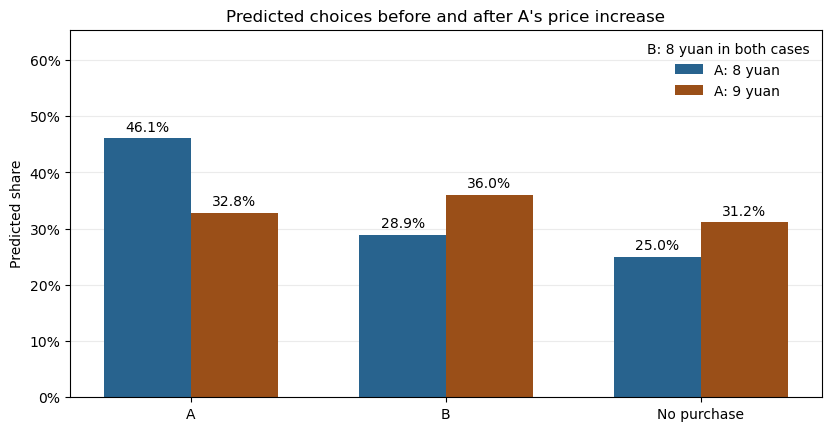

In [4]:
positions = np.arange(len(alternatives))
bar_width = 0.34
fig, ax = plt.subplots(figsize=(8.2, 4.2), layout="constrained")
before_bars = ax.bar(
    positions - bar_width / 2, baseline_shares, bar_width,
    color="#28638e", label="A: 8 yuan",
)
after_bars = ax.bar(
    positions + bar_width / 2, higher_price_shares, bar_width,
    color="#9a4f18", label="A: 9 yuan",
)
for bars in (before_bars, after_bars):
    ax.bar_label(bars, labels=[f"{bar.get_height():.1%}" for bar in bars], padding=3)
ax.set_xticks(positions, alternatives)
ax.set_ylim(0, 1.42 * max(baseline_shares.max(), higher_price_shares.max()))
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set(ylabel="Predicted share", title="Predicted choices before and after A's price increase")
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
ax.legend(title="B: 8 yuan in both cases", loc="upper right", frameon=False)
plt.show()

默认估计下，A 的份额减少约 **13.26 个百分点**，B 的份额增加约 **7.11 个百分点**，不购买份额增加约 **6.15 个百分点**。两项增加量之和等于 A 的份额损失。这里比较的是两个模型情景下的总体份额。每位顾客在模拟数据中只面对一组实际报价，仅凭这些记录无法确认某位顾客在另一组报价下会怎么选。

## 5. 什么决定流失的份额如何分配？

比较两个方案中的 B 和不购买。两个概率共用分母，取比值后分母消掉。

$$
\frac{P_{iB}}{P_{i0}}=\exp(V_{iB}).
$$

只改变 A 的价格，B 的系统性效用和不购买的系统性效用都保持不变，所以 B 对不购买的相对概率不变。这是多项 Logit 的**无关选项独立性**（independence of irrelevant alternatives, IIA）在本例中的表现。A 的份额减少后，B 和不购买按它们原来的相对大小分走这部分份额。这里两种方案都向所有顾客统一报价，并使用同一组偏好参数，因此这一关系也能用预测份额表达。

In [5]:
odds_before = baseline_shares[1] / baseline_shares[2]
odds_after = higher_price_shares[1] / higher_price_shares[2]
assert np.isclose(odds_before, odds_after)
print(f"B 对不购买的份额之比  {odds_before:.4f} → {odds_after:.4f}")

if changes[0] < 0:
    b_fraction = baseline_shares[1] / (baseline_shares[1] + baseline_shares[2])
    assert np.isclose(b_fraction, changes[1] / -changes[0])
    print(f"基准下 B 在其与不购买两项中的份额  {b_fraction:.1%}")

B 对不购买的份额之比  1.1545 → 1.1545
基准下 B 在其与不购买两项中的份额  53.6%


当 A 和 B 用途相近时，同一个顾客需求可能同时提高两件商品的未观测吸引力。如果两项冲击因此相关，流失份额未必还会按上述比例分配。下一课转向报价机制。商店若根据研究者看不到的购买意愿报价，这些价格还能否用来估计需求？

## 动手练习

1. **核对份额。** 用 `predict_shares(10, 8, fit.x)` 计算 A 涨至 10 元后的预测份额。和基准份额比较，用百分点报告三个选项各自的份额变化，检查它们相加是否为零。
2. **比较 B 的承接比例。** 把 B 的报价设为 7 元，分别计算 A 报 8 元和 9 元的预测份额，算出 B 增加的份额占 A 流失份额的比例。它和 B 报 8 元时的比例有什么差异？用 $\exp(V_B)$ 解释。
3. **区分单独提价和同时改价。** 比较 $(p_A,p_B)=(8,8)$ 和 $(9,9)$。检查 B 对不购买的相对概率是否保持不变，并指出推导中的哪个条件发生了变化。
4. **讨论替代假设。** 假设 A 和 B 是同一口味的两种容量。给出一个可能使顾客更倾向于在 A 和 B 之间切换的未观测因素，并说明它会破坏哪项模型假设。